# 03 — LTLA-Level Covariates

**Project:** Machine Learning vs Regression for COVID-19 Case Prediction via Wastewater-Based Epidemiology
**Author:** Sebastian Munteanu · Department of Mathematical Sciences, University of Bath

---

This notebook builds the $\mathbf{z}_i$ term of the model — the local authority characteristics that go alongside the wastewater signal.

These are what the authority-level dataset makes possible. Merging at regional level was rejected partly because it would leave *"no reasonable way to introduce the covariates"*, whereas working at LTLA level *"would then be possible to develop covariates at LTLA level, which would significantly add to the scientific interest of the dataset."* This notebook is that step: it is what the whole STW→LTLA bridge was built to make possible.

## What gets built

| Covariate | Source | Why it might matter |
|---|---|---|
| % under 18, % 65+, median age | ONS mid-2019 single-year-of-age estimates | Age structure drives both transmission and testing behaviour; older populations were shielding and vaccinated earlier |
| Population density | ONS Standard Area Measurements 2011 | Transmission is denser where people are denser |
| IMD score | English Indices of Deprivation 2019 | Deprivation tracked COVID incidence strongly; also correlates with household size and key-worker share |
| Income, health, living-environment domains | as above | Sub-domains, in case the composite index blurs the mechanism |

## One method note that applies throughout

All of these are published at **LSOA** level (or, for deprivation, at LSOA level with 2019 council codes attached). None of it is published against the 2021 local authority boundaries this project uses.

Rather than take a ready-made local-authority summary — which would reintroduce exactly the boundary-vintage problem that notebook 01 had to fix — each source is aggregated from LSOAs to 2021 authorities here, reusing the same `LSOA11CD → LAD21CD` lookup. LSOA codes are stable across all these vintages, so this sidesteps the reorganisations entirely.

Counts and areas are **summed**. Scores and rates are **population-weighted averaged**, since an unweighted mean across LSOAs would let a tiny LSOA count as much as a large one.

## Why this notebook exists

The first two notebooks produced a dataset linking sewage readings to case counts. This one adds a third ingredient: **what kind of place each local authority is**.

The reason is that the same wastewater concentration does not mean the same thing everywhere. A reading from a dense, deprived inner-city borough with a young population is not directly comparable to the same reading from a sparse, affluent rural district full of retirees — the underlying transmission, testing behaviour and vulnerability all differ. Giving the model information about the place lets it account for some of that.

This is only possible because the data is at local authority level. Had the project worked at regional level, with nine regions instead of three hundred authorities, there would be too few units for characteristics like these to be informative.

Four things get built here, from four different public sources, and all of them need the same treatment: they are published for LSOAs or for older council boundaries, and have to be aggregated onto the 2021 authorities the rest of the project uses.

## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')

# ---------------------------------------------------------------------------
# Paths. Nothing here needs editing: the project root is found automatically,
# whether the notebook is run from the notebooks/ folder or from the root.
# ---------------------------------------------------------------------------
PROJECT = Path.cwd()
if PROJECT.name == 'notebooks':
    PROJECT = PROJECT.parent
DATA = PROJECT / 'data'          # all input files live here
OUT  = PROJECT / 'output'        # everything the notebooks produce goes here
OUT.mkdir(exist_ok=True)
assert DATA.exists(), f'Could not find a data folder at {DATA} - run this notebook from inside the project folder'
pd.set_option('display.width', 150)

# the dashboard reports these pairs as single units; the panel follows the same convention
REPORTING_FOLD = {'E09000001': 'E09000012', 'E06000053': 'E06000052'}
FOLD_NAMES     = {'E09000012': 'Hackney and City of London',
                  'E06000052': 'Cornwall and Isles of Scilly'}
fold = lambda c: REPORTING_FOLD.get(c, c)

lsoa_lad = pd.read_excel(DATA / 'LSOA11_WD21_LAD21_EW_LU_V2.xlsx',
                         sheet_name='LSOA11_WD21_LAD21_EW_LU')[['LSOA11CD','LAD21CD','LAD21NM']]
lsoa_lad['LAD21CD'] = lsoa_lad.LAD21CD.map(fold)
assert lsoa_lad.LSOA11CD.is_unique
print(f'LSOA -> LAD21 lookup: {len(lsoa_lad):,} LSOAs -> {lsoa_lad.LAD21CD.nunique()} authorities')

LSOA -> LAD21 lookup: 34,753 LSOAs -> 329 authorities


## 2. Age structure

From `SAPE22DT2`, the same ONS mid-2019 file notebook 01 used for populations. Only the *All Ages* column was needed there; the file also carries a column per single year of age from 0 to 89 plus a 90+ bucket, so age structure needs no new download.

Median age is computed from the cumulative age distribution rather than approximated, taking the first age at which the cumulative share passes 50%. The 90+ bucket is treated as age 92 — it only affects authorities whose median would fall in that bucket, of which there are none.

In [2]:
syoa = pd.read_excel(DATA / 'SAPE22DT2-mid-2019-lsoa-syoa-estimates-unformatted.xlsx',
                     sheet_name='Mid-2019 Persons', skiprows=4)
AGE_COLS = [c for c in syoa.columns if isinstance(c, int)] + ['90+']
print(f'single-year-of-age columns: {len(AGE_COLS)} (0 to 89, plus 90+)')

a = (syoa.rename(columns={'LSOA Code': 'LSOA11CD'})[['LSOA11CD'] + AGE_COLS]
        .merge(lsoa_lad[['LSOA11CD','LAD21CD']], on='LSOA11CD'))
by_age = a.groupby('LAD21CD')[AGE_COLS].sum()
total  = by_age.sum(axis=1)

ages = np.array([c if isinstance(c, int) else 92 for c in AGE_COLS], dtype=float)
cumshare = by_age[AGE_COLS].cumsum(axis=1).div(total, axis=0)

age = pd.DataFrame({
    'ltla_pop'    : total,
    'pct_under18' : 100 * by_age[[c for c in AGE_COLS if isinstance(c, int) and c < 18]].sum(axis=1) / total,
    'pct_65plus'  : 100 * by_age[[c for c in AGE_COLS if isinstance(c, int) and c >= 65] + ['90+']].sum(axis=1) / total,
    'median_age'  : cumshare.apply(lambda r: ages[np.searchsorted(r.values, 0.5)], axis=1),
}).reset_index()

assert np.isclose(age.ltla_pop.sum(), syoa['All Ages'].sum()), 'population lost in aggregation'
print(f'{len(age)} authorities | total population {age.ltla_pop.sum():,.0f}')

single-year-of-age columns: 91 (0 to 89, plus 90+)
329 authorities | total population 59,439,840


In [3]:
names = lsoa_lad[['LAD21CD','LAD21NM']].drop_duplicates('LAD21CD')
chk = age.merge(names, on='LAD21CD')
chk['LAD21NM'] = chk.apply(lambda r: FOLD_NAMES.get(r.LAD21CD, r.LAD21NM), axis=1)
print('Oldest three:');  display(chk.nlargest(3, 'pct_65plus')[['LAD21NM','pct_65plus','median_age']].round(1))
print('Youngest three:'); display(chk.nsmallest(3, 'pct_65plus')[['LAD21NM','pct_65plus','median_age']].round(1))

Oldest three:


,LAD21NM,pct_65plus,median_age
167,North Norfolk,33.2,54.0
88,Rother,32.1,53.0
77,East Devon,30.4,51.0


Youngest three:


,LAD21NM,pct_65plus,median_age
303,Tower Hamlets,6.4,31.0
298,Newham,7.7,32.0
285,Hackney and City of London,8.0,33.0


This is a real check rather than a decorative one: North Norfolk and Rother are consistently the oldest districts in England and Tower Hamlets the youngest. Recovering that ordering from the LSOA aggregation is evidence the lookup is joining correctly — an error in the LSOA→LTLA mapping would scramble it.

## 3. Population density

ONS Standard Area Measurements for 2011 census areas. Four area measures are published; **`AREALHECT`** (land area in hectares) is used, which excludes inland water. Density on the "extent of the realm" measure would understate authorities with large lakes or estuaries.

Note the file is Latin-1 encoded, not UTF-8 — reading it as UTF-8 fails partway through on a stray byte.

In [4]:
sam = pd.read_csv(DATA / 'SAM_for_2011_Census_Areas' / 'SAM_LSOA_DEC_2011_EW.csv',
                  encoding='latin-1')[['LSOA11CD','AREALHECT']]

area = (sam.merge(lsoa_lad[['LSOA11CD','LAD21CD']], on='LSOA11CD')
           .groupby('LAD21CD', as_index=False).AREALHECT.sum())

dens = area.merge(age[['LAD21CD','ltla_pop']], on='LAD21CD')
dens['density_per_km2'] = dens.ltla_pop / (dens.AREALHECT / 100)   # 100 ha = 1 km^2
dens['log_density']     = np.log10(dens.density_per_km2)

print(f'density ranges from {dens.density_per_km2.min():,.0f} to {dens.density_per_km2.max():,.0f} people/km2 '
      f'— a factor of {dens.density_per_km2.max()/dens.density_per_km2.min():.0f}')
print('This is why density enters the model on a log scale.')

density ranges from 25 to 16,427 people/km2 — a factor of 661
This is why density enters the model on a log scale.


## 4. Deprivation

English Indices of Deprivation 2019, **File 7** — the LSOA-level file.

The ready-made local authority summary (File 10) would have been less work, but it is published against **2019** council boundaries. Using it would have dragged the Buckinghamshire and Northamptonshire vintage problem from notebook 01 back into the analysis. Aggregating the LSOA file here avoids that, and gives access to the individual domains as a bonus.

Scores are weighted by each LSOA's population denominator (mid-2015, the vintage IMD 2019 itself uses) rather than averaged flat.

A note : **IMD is an ordinal-ish composite**, and averaging its scores across LSOAs is a convention rather than a theoretically clean operation. The ONS local authority summaries do the same thing, so it is standard practice, but it is an assumption rather than a fact.

In [5]:
DOMAINS = {
    'Index of Multiple Deprivation (IMD) Score'  : 'imd_score',
    'Income Score (rate)'                        : 'income_score',
    'Health Deprivation and Disability Score'    : 'health_score',
    'Living Environment Score'                   : 'living_env_score',
}
POP_COL = 'Total population: mid 2015 (excluding prisoners)'

imd = pd.read_csv(DATA / 'File_7_-_All_IoD2019_Scores__Ranks__Deciles_and_Population_Denominators_3.csv')
print(f'IMD file: {imd.shape[0]:,} LSOAs x {imd.shape[1]} columns')

i = (imd.rename(columns={'LSOA code (2011)': 'LSOA11CD', POP_COL: 'w', **DOMAINS})
        [['LSOA11CD','w'] + list(DOMAINS.values())]
        .merge(lsoa_lad[['LSOA11CD','LAD21CD']], on='LSOA11CD'))

dep = (i.groupby('LAD21CD')
        .apply(lambda t: pd.Series({k: np.average(t[k], weights=t.w) for k in DOMAINS.values()}),
               include_groups=False)
        .reset_index())
print(f'{len(dep)} authorities')

IMD file: 32,844 LSOAs x 57 columns


307 authorities


## 5. Assemble and check

In [6]:
cov = (age.merge(dens[['LAD21CD','AREALHECT','density_per_km2','log_density']], on='LAD21CD')
          .merge(dep, on='LAD21CD')
          .merge(names, on='LAD21CD'))
cov['LAD21NM'] = cov.apply(lambda r: FOLD_NAMES.get(r.LAD21CD, r.LAD21NM), axis=1)

panel_ltlas = set(pd.read_csv(OUT / 'rna_cases_panel.csv', usecols=['LAD21CD']).LAD21CD.unique())
cov = cov[cov.LAD21CD.isin(panel_ltlas)].reset_index(drop=True)

assert set(cov.LAD21CD) == panel_ltlas, 'covariates do not cover every LTLA in the panel'
assert cov.notna().all().all(), 'missing values in covariates'
print(f'covariates: {cov.shape[0]} authorities x {cov.shape[1]} columns — matches the panel exactly, no gaps')
display(cov.describe().round(2).T[['mean','std','min','50%','max']])

covariates: 307 authorities x 13 columns — matches the panel exactly, no gaps


,mean,std,min,50%,max
ltla_pop,183345.15,123325.76,39927.00,141771.00,1141816.00
pct_under18,20.98,2.22,15.59,20.69,29.85
pct_65plus,19.72,4.86,6.42,19.64,33.17
median_age,41.73,5.13,28.00,42.00,54.00
AREALHECT,42435.97,58694.57,1212.95,21095.75,501301.83
density_per_km2,1822.25,2660.63,24.86,750.23,16426.98
log_density,2.88,0.61,1.40,2.88,4.22
imd_score,19.79,7.97,5.54,18.62,45.04
income_score,0.12,0.05,0.04,0.11,0.25
health_score,-0.12,0.63,-1.55,-0.13,1.64


In [7]:
print('Densest three:');       display(cov.nlargest(3,'density_per_km2')[['LAD21NM','density_per_km2','imd_score']].round(1))
print('Sparsest three:');      display(cov.nsmallest(3,'density_per_km2')[['LAD21NM','density_per_km2','imd_score']].round(1))
print('Most deprived three:'); display(cov.nlargest(3,'imd_score')[['LAD21NM','imd_score','income_score']].round(2))
print('Least deprived three:');display(cov.nsmallest(3,'imd_score')[['LAD21NM','imd_score','income_score']].round(2))

Densest three:


,LAD21NM,density_per_km2,imd_score
303,Tower Hamlets,16427.0,27.9
292,Islington,16317.3,27.5
285,Hackney and City of London,13243.3,32.1


Sparsest three:


,LAD21NM,density_per_km2,imd_score
67,Eden,24.9,16.3
174,Ryedale,36.8,15.7
173,Richmondshire,40.7,12.1


Most deprived three:


,LAD21NM,imd_score,income_score
8,Blackpool,45.04,0.25
249,Knowsley,43.01,0.25
250,Liverpool,42.41,0.23


Least deprived three:


,LAD21NM,imd_score,income_score
113,Hart,5.54,0.04
38,Wokingham,5.85,0.04
183,Rushcliffe,7.18,0.06


All four lists are what independent knowledge of England would predict — Tower Hamlets and Islington densest, the rural Cumbrian and North Yorkshire districts sparsest, Blackpool the most deprived authority in the country, Hart and Wokingham the least. Nothing here was tuned to produce that; it falls out of the aggregation, which is the point of showing it.

## 6. How the covariates relate to each other

Worth looking at before modelling, because strongly correlated covariates will make individual coefficients hard to interpret even when the model as a whole is fine.

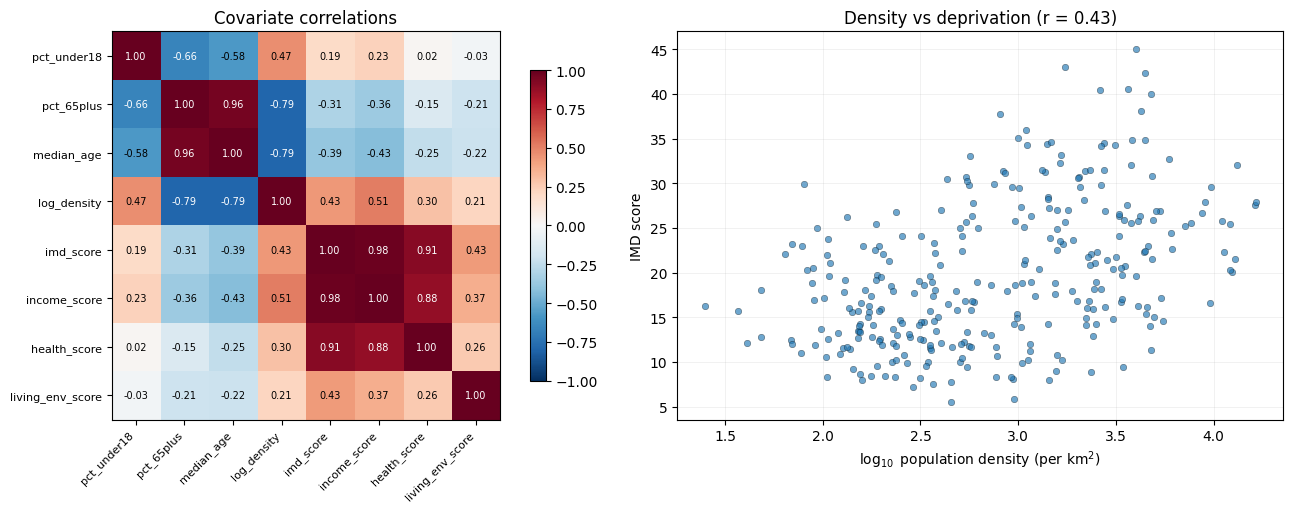

In [8]:
NUM = ['pct_under18','pct_65plus','median_age','log_density','imd_score','income_score','health_score','living_env_score']
corr = cov[NUM].corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
im = axes[0].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[0].set(xticks=range(len(NUM)), yticks=range(len(NUM)), title='Covariate correlations')
axes[0].set_xticklabels(NUM, rotation=45, ha='right', fontsize=8); axes[0].set_yticklabels(NUM, fontsize=8)
for x in range(len(NUM)):
    for y in range(len(NUM)):
        axes[0].text(y, x, f'{corr.iloc[x,y]:.2f}', ha='center', va='center', fontsize=7,
                     color='white' if abs(corr.iloc[x,y]) > 0.6 else 'black')
fig.colorbar(im, ax=axes[0], shrink=0.8)

axes[1].scatter(cov.log_density, cov.imd_score, s=22, alpha=0.65, edgecolor='k', linewidth=0.3)
axes[1].set(xlabel='$\\log_{10}$ population density (per km$^2$)', ylabel='IMD score',
            title=f'Density vs deprivation (r = {cov.log_density.corr(cov.imd_score):.2f})')
axes[1].grid(alpha=0.25, lw=0.5)
fig.tight_layout(); plt.show()

Two relationships to keep in mind when reading coefficients later. Median age is nearly a linear function of the two age shares, so all three should not be interpreted as independent effects. And density and deprivation are positively correlated — denser authorities are more deprived on average — so a model containing both is splitting a shared signal between them.

Neither is a reason to drop anything: for *prediction* correlated covariates are harmless, and the model is judged on held-out error. It only matters if individual $\gamma$ coefficients are given a causal reading, which they should not be.

## 7. Vaccination uptake — a time-varying covariate

Everything above is **static**: fixed for an authority across the whole study window, so it can shift that authority's level but cannot track how its situation changes. Vaccination uptake is different. It varies within an authority over time, and over June–September 2021 it was moving fast — second-dose coverage roughly doubled.

Source: the UKHSA dashboard archive, the same place the case data came from, so the format matches.

`cumVaccinationFirstDoseUptakeByVaccinationDatePercentage` and the second-dose equivalent, both cumulative percentages by vaccination date.

**One harmonisation trap.** These are *percentages*, not counts, so they cannot be summed when merging the legacy Buckinghamshire and Northamptonshire districts onto their 2021 unitary codes — adding four district percentages would give a figure near 300%. They are combined as a **population-weighted mean** instead, using each legacy district's own mid-2019 population as the weight.

In [9]:
VAX = DATA / 'Vaccinations'
crosswalk = pd.read_csv(OUT / 'lad11_to_lad21.csv')
lad_map = dict(zip(crosswalk.LAD11CD, crosswalk.LAD21CD))

# population of each 2011-vintage district, for weighting the merges
oa = pd.read_csv(DATA / ('Output_Area_to_Lower_layer_Super_Output_Area_to_Middle_layer_'
                         'Super_Output_Area_to_Local_Authority_District_(December_2011)_'
                         'Lookup_in_England_and_Wales.csv'), low_memory=False)
lsoa_lad11 = oa[['LSOA11CD','LAD11CD']].drop_duplicates()
pop_lsoa = (syoa.rename(columns={'LSOA Code':'LSOA11CD','All Ages':'pop'})[['LSOA11CD','pop']]
                .dropna(subset=['LSOA11CD']))
pop11 = lsoa_lad11.merge(pop_lsoa, on='LSOA11CD').groupby('LAD11CD')['pop'].sum()
weights = pop11.to_dict()

def load_uptake(fname, colname):
    c = pd.read_csv(VAX / fname, usecols=['date','area_code','value'])
    c = c[c.area_code.str.startswith('E')].copy()
    c['date'] = pd.to_datetime(c['date'], format='%Y-%m-%d')
    c = c[c.date.between('2021-05-01','2021-09-20')].copy()
    c['LAD21CD'] = c.area_code.map(lad_map).fillna(c.area_code).map(fold)
    c['w'] = c.area_code.map(weights).fillna(1.0)
    out = (c.groupby(['LAD21CD','date'])
             .apply(lambda t: np.average(t.value, weights=t.w), include_groups=False)
             .rename(colname).reset_index())
    print(f'{colname:16s}: {len(c):,} raw rows -> {len(out):,} authority-days, '
          f'{out.LAD21CD.nunique()} authorities')
    return out

v1 = load_uptake('ltla_cumVaccinationFirstDoseUptakeByVaccinationDatePercentage.csv',  'vacc_dose1_pct')
v2 = load_uptake('ltla_cumVaccinationSecondDoseUptakeByVaccinationDatePercentage.csv', 'vacc_dose2_pct')
vacc = v1.merge(v2, on=['LAD21CD','date'], how='outer').sort_values(['LAD21CD','date'])

# cumulative uptake must never fall
mono = vacc.groupby('LAD21CD').vacc_dose1_pct.apply(lambda s: (s.diff().dropna() >= -0.05).all()).all()
assert mono, 'cumulative uptake decreases somewhere - check the harmonisation'
print(f'\ncumulative uptake is monotone within every authority: {mono}')

vacc_dose1_pct  : 45,045 raw rows -> 43,901 authority-days, 307 authorities


vacc_dose2_pct  : 45,045 raw rows -> 43,901 authority-days, 307 authorities

cumulative uptake is monotone within every authority: True


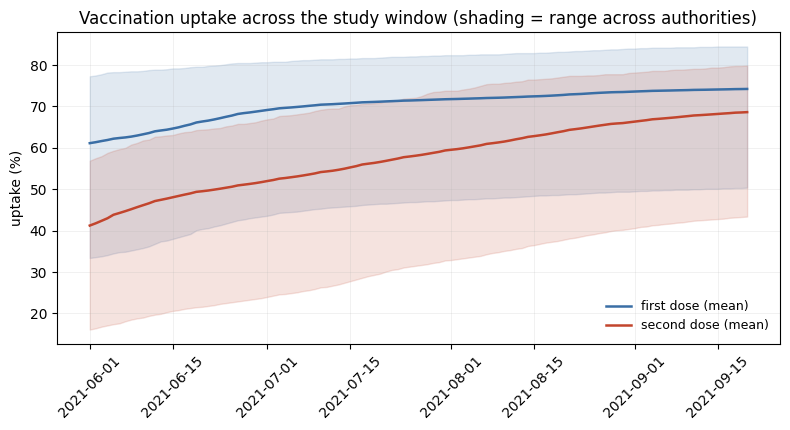

saved: ltla_vaccination.csv  (43,901 rows)
            vacc_dose1_pct  vacc_dose2_pct
date                                      
2021-06-01            62.7            44.8
2021-06-15            66.7            49.8
2021-06-29            69.8            53.0
2021-07-13            71.1            56.5
2021-07-27            71.8            59.8
2021-08-10            72.6            63.2
2021-08-24            73.5            66.1
2021-09-07            74.1            68.0


In [10]:
window = vacc[vacc.date.between('2021-06-01','2021-09-20')]
fig, ax = plt.subplots(figsize=(8, 4.4))
for col, c, lab in [('vacc_dose1_pct','#3a6ea5','first dose'), ('vacc_dose2_pct','#c2452d','second dose')]:
    m = window.groupby('date')[col].agg(['mean','min','max'])
    ax.plot(m.index, m['mean'], color=c, lw=1.8, label=f'{lab} (mean)')
    ax.fill_between(m.index, m['min'], m['max'], color=c, alpha=0.15)
ax.set(ylabel='uptake (%)', title='Vaccination uptake across the study window (shading = range across authorities)')
ax.legend(frameon=False, fontsize=9); ax.grid(alpha=0.25, lw=0.5)
ax.tick_params(axis='x', rotation=45); fig.tight_layout(); plt.show()

vacc.to_csv(OUT / 'ltla_vaccination.csv', index=False)
print(f'saved: ltla_vaccination.csv  ({len(vacc):,} rows)')
print(window.groupby('date')[['vacc_dose1_pct','vacc_dose2_pct']].mean().resample('14D').mean().round(1).to_string())

Second-dose uptake climbs from roughly 45% to 68% over the window while first-dose flattens, so the second dose is the more informative of the two. The spread across authorities is wide and persistent, which is what makes this useful as a covariate rather than just a national time trend.

## 8. Save

In [11]:
cov.to_csv(OUT / 'ltla_covariates.csv', index=False)
print(f'saved: ltla_covariates.csv  ({len(cov)} rows x {cov.shape[1]} columns)')
display(cov.head())

saved: ltla_covariates.csv  (307 rows x 13 columns)


,LAD21CD,ltla_pop,pct_under18,pct_65plus,median_age,AREALHECT,density_per_km2,log_density,imd_score,income_score,health_score,living_env_score,LAD21NM
0,E06000001,93663,21.410803,19.429230,41.0,9386.11,997.889434,2.999082,35.036693,0.228315,0.868537,6.943125,Hartlepool
1,E06000002,140980,23.261456,16.383884,36.0,5387.47,2616.812715,3.417773,40.460346,0.251208,1.193741,12.928813,Middlesbrough
2,E06000003,137150,20.129785,22.627780,45.0,24489.51,560.035705,2.748216,29.791706,0.186187,0.789854,7.793080,Redcar and Cleveland
3,E06000004,197348,22.218619,18.456230,40.0,20393.06,967.721372,2.985750,25.789576,0.163999,0.684090,6.007198,Stockton-on-Tees
4,E06000005,106803,21.093977,20.539685,43.0,19747.51,540.842871,2.733071,25.657303,0.153240,0.531791,8.800320,Darlington


## 8.1 What is in the finished files

### `ltla_covariates.csv` — fixed characteristics, one row per authority

These describe what kind of place each authority is. They do not change over the study period.

| Column | Meaning | Why it might matter for COVID-19 |
|---|---|---|
| `LAD21CD`, `LAD21NM` | Authority code and name | Identifies the row |
| `ltla_pop` | Resident population, mid-2019 | Bigger places have more cases simply because more people live there |
| `pct_under18` | Share of residents under 18 | Children were largely unvaccinated in 2021 and mixed heavily once schools reopened |
| `pct_65plus` | Share of residents 65 and over | Vaccinated earliest, and more likely to have been shielding |
| `median_age` | Median age of residents | A single summary of the age profile |
| `AREALHECT` | Land area in hectares, excluding inland water | Used to compute density |
| `density_per_km2` | Residents per square kilometre | Denser places mean more contact between people |
| `log_density` | Base-10 logarithm of the above | Density spans a factor of 660 across England, so models use the log |
| `imd_score` | Index of Multiple Deprivation, population-weighted average across the authority's LSOAs | Deprivation tracked COVID-19 incidence strongly. Higher means more deprived. |
| `income_score` | Share of the population experiencing income deprivation | A single component of IMD, in case the composite blurs the mechanism |
| `health_score` | Health deprivation and disability score | As above. Standardised, so it can be negative. |
| `living_env_score` | Living environment score — housing quality, air quality | As above |

**Reading the deprivation scores.** IMD is a rank-based composite, so its units are not intuitive on their own. What matters is the ordering and the spread. Across the 307 authorities here it runs from about 5.5 (Hart, in Hampshire) to 45 (Blackpool), with a median near 19.

### `ltla_vaccination.csv` — uptake, one row per authority per day

| Column | Meaning |
|---|---|
| `LAD21CD` | Authority code |
| `date` | The day |
| `vacc_dose1_pct` | Percentage of the eligible population who have had a first dose by this date, cumulative |
| `vacc_dose2_pct` | The same for second doses |

This is the only characteristic in the project that changes over time, which makes it different in kind from everything in the file above. Over the study window first-dose uptake went from about 63% to 74% and second-dose from about 45% to 68%.

## 9. Summary

`ltla_covariates.csv` holds one row per local authority with age structure, population density and deprivation, all aggregated from LSOA level onto the 2021 boundaries the rest of the project uses. It covers every authority in the panel with no missing values.

**Recorded decisions**

| Decision | Choice | Reason |
|---|---|---|
| Aggregation route | LSOA → LAD21 directly | Avoids the boundary-vintage problem that ready-made LAD summaries carry |
| Weighting for scores | Population-weighted | An unweighted mean lets a small LSOA count as much as a large one |
| Area measure | Land area (`AREALHECT`) | Excludes inland water, which would distort coastal and lakeland authorities |
| Density scale | $\log_{10}$ | Spans nearly three orders of magnitude across England |
| Population vintage | ONS mid-2019 | Matches the vintage used throughout notebooks 01 and 02 |

**Two outputs**

- `ltla_covariates.csv` — the static covariates $\mathbf{z}_i$, one row per authority
- `ltla_vaccination.csv` — vaccination uptake $z_{it}$, one row per authority per day

**Not included:** rural/urban classification, largely redundant given log density and only published against older boundary vintages.